# CSET485  AI & Society  Assignment 1 

In [1]:
import os, json, warnings, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, "to_string") else value)

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     GridSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, r2_score, mean_squared_error, roc_curve)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

# ---------------------------------------------------------------- configuration
ROLL_NUMBER      = "S24BCAU0051"          # last digit 1 -> COMPAS track
MASTER_SEED      = int(ROLL_NUMBER[-3:])   # last three digits -> 051 (assignment rule)
TEST_FRACTION    = 0.30
CV_FOLDS         = 5
WINSOR_QUANTILE  = 0.99                    # outlier cap, estimated on TRAIN rows only
USE_RACE_FEATURE = True                    # flip to False for the "unawareness" run
DATA_URL         = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"
DATA_CANDIDATES  = ["data/compas-scores-two-years.csv", "compas-scores-two-years.csv"]

RESULTS_DIR, PLOTS_DIR = Path("results"), Path("plots")
for _d in (RESULTS_DIR, PLOTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

np.random.seed(MASTER_SEED)
RUN_LOG = {"roll_number": ROLL_NUMBER, "seed": MASTER_SEED}   # every headline number lands here

def save_table(frame, name, index=True, digits=4):
    out = frame.round(digits)
    out.to_csv(RESULTS_DIR / f"{name}.csv", index=index)
    return out

def save_figure(fig, name):
    fig.savefig(PLOTS_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

print(f"seed={MASTER_SEED} | test fraction={TEST_FRACTION} | CV folds={CV_FOLDS}")

seed=51 | test fraction=0.3 | CV folds=5


In [2]:
def load_compas_csv(candidates, fallback_url):
    for path in candidates:
        if os.path.exists(path):
            print("loading local file:", path)
            return pd.read_csv(path)
    print("no local copy found - downloading from ProPublica")
    return pd.read_csv(fallback_url)

raw_compas = load_compas_csv(DATA_CANDIDATES, DATA_URL)
RUN_LOG["n_rows_raw"] = int(len(raw_compas))
print("raw shape:", raw_compas.shape)

# --- missing-value audit (only columns that actually contain NaNs) ---
audit_cols = ["days_b_screening_arrest", "c_jail_in", "c_jail_out", "c_case_number",
              "c_charge_desc", "in_custody", "out_custody"]
missing_audit = (raw_compas[audit_cols].isna().sum().rename("n_missing").to_frame()
                 .assign(pct_missing=lambda t: 100 * t.n_missing / len(raw_compas)))
display(save_table(missing_audit, "p1_missing_value_audit"))
print("\nraw class balance (two_year_recid):", raw_compas.two_year_recid.value_counts(normalize=True).round(3).to_dict())

loading local file: data/compas-scores-two-years.csv
raw shape: (7214, 53)


,n_missing,pct_missing
days_b_screening_arrest,307,4.2556
c_jail_in,307,4.2556
c_jail_out,307,4.2556
c_case_number,22,0.3050
c_charge_desc,29,0.4020
in_custody,236,3.2714
out_custody,236,3.2714



raw class balance (two_year_recid): {0: 0.549, 1: 0.451}


In [3]:
def apply_compas_filters(frame):
    steps = [
        ("arrest within 30 days of screening",
         lambda f: f["days_b_screening_arrest"].between(-30, 30)),
        ("recidivism outcome observed", lambda f: f["is_recid"] != -1),
        ("charge degree is F or M",     lambda f: f["c_charge_degree"] != "O"),
        ("valid COMPAS score_text",     lambda f: f["score_text"] != "N/A"),
    ]
    rows, current = [("raw file", len(frame), 0)], frame
    for label, rule in steps:
        before = len(current)
        current = current[rule(current)]
        rows.append((label, len(current), before - len(current)))
    return current.copy(), pd.DataFrame(rows, columns=["step", "rows_left", "rows_dropped"])

compas_clean, attrition_table = apply_compas_filters(raw_compas)
display(save_table(attrition_table, "p1_filter_attrition", index=False))

# decile_score must lie in 1..10 and screening date must parse
compas_clean["screen_dt"] = pd.to_datetime(compas_clean["compas_screening_date"], errors="coerce")
assert compas_clean["decile_score"].between(1, 10).all(), "decile_score outside 1-10"
assert compas_clean["screen_dt"].notna().all(), "unparseable screening date"
print("decile range:", compas_clean.decile_score.min(), "-", compas_clean.decile_score.max(),
      "| screening dates:", compas_clean.screen_dt.min().date(), "->", compas_clean.screen_dt.max().date())
RUN_LOG["n_rows_clean"] = int(len(compas_clean))
RUN_LOG["base_rate_recid_clean"] = float(compas_clean.two_year_recid.mean())
print("clean rows:", len(compas_clean), "| 2-yr recidivism rate:", round(compas_clean.two_year_recid.mean(), 4))
print("residual NaNs in modelling columns:",
      int(compas_clean[["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count",
                        "c_jail_in", "c_jail_out", "sex", "race", "c_charge_degree"]].isna().sum().sum()))

,step,rows_left,rows_dropped
0,raw file,7214,0
1,arrest within 30 days of screening,6172,1042
2,recidivism outcome observed,6172,0
3,charge degree is F or M,6172,0
4,valid COMPAS score_text,6172,0


decile range: 1 - 10 | screening dates: 2013-01-01 -> 2014-12-31
clean rows: 6172 | 2-yr recidivism rate: 0.4551
residual NaNs in modelling columns: 0


In [4]:
RACE_DUMMIES = ["race_african_american", "race_hispanic", "race_other"]   # reference: Caucasian
COUNT_COLUMNS = ["priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count", "jail_days"]

def engineer_features(frame):
    out = frame.copy()
    out["is_male"]   = (out["sex"] == "Male").astype(int)
    out["is_felony"] = (out["c_charge_degree"] == "F").astype(int)
    stay = (pd.to_datetime(out["c_jail_out"]) - pd.to_datetime(out["c_jail_in"])).dt.total_seconds() / 86400
    out["jail_days"] = stay.clip(lower=0)
    out["race_group"] = out["race"].replace({"Asian": "Other", "Native American": "Other"})
    out["race_african_american"] = (out["race_group"] == "African-American").astype(int)
    out["race_hispanic"]         = (out["race_group"] == "Hispanic").astype(int)
    out["race_other"]            = (out["race_group"] == "Other").astype(int)
    return out

compas_feat = engineer_features(compas_clean)

# ---- train / test split (70 / 30, roll-number seed, stratified on the binary outcome) ----
train_ids, test_ids = train_test_split(compas_feat.index, test_size=TEST_FRACTION,
                                       random_state=MASTER_SEED, stratify=compas_feat["two_year_recid"])
train_frame = compas_feat.loc[train_ids].copy()
test_frame  = compas_feat.loc[test_ids].copy()
print("train:", train_frame.shape, "| test:", test_frame.shape)
print("recid rate  train / test:", round(train_frame.two_year_recid.mean(), 4), "/", round(test_frame.two_year_recid.mean(), 4))

# ---- outlier handling: winsorise long-tailed counts at the TRAIN 99th percentile ----
def fit_winsor_caps(train_part, columns, q):
    return {c: max(float(train_part[c].quantile(q)), 1.0) for c in columns}

def apply_winsor_caps(frame, caps):
    out, touched = frame.copy(), {}
    for col, cap in caps.items():
        touched[col] = int((out[col] > cap).sum())
        out[col] = out[col].clip(upper=cap)
    return out, touched

winsor_caps = fit_winsor_caps(train_frame, COUNT_COLUMNS, WINSOR_QUANTILE)
train_frame, n_cap_train = apply_winsor_caps(train_frame, winsor_caps)
test_frame,  n_cap_test  = apply_winsor_caps(test_frame,  winsor_caps)
outlier_report = pd.DataFrame({"cap_from_train": winsor_caps, "train_cells_capped": n_cap_train,
                               "test_cells_capped": n_cap_test})
display(save_table(outlier_report, "p1_outlier_caps"))

# ---- final feature list ----
FEATURE_COLUMNS = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count",
                   "jail_days", "is_felony", "is_male"] + (RACE_DUMMIES if USE_RACE_FEATURE else [])
TARGET_BINARY, TARGET_SCORE = "two_year_recid", "decile_score"
X_train, X_test = train_frame[FEATURE_COLUMNS], test_frame[FEATURE_COLUMNS]
y_train_bin, y_test_bin = train_frame[TARGET_BINARY], test_frame[TARGET_BINARY]
y_train_score, y_test_score = train_frame[TARGET_SCORE], test_frame[TARGET_SCORE]
print("features:", FEATURE_COLUMNS)

train: (4320, 61) | test: (1852, 61)
recid rate  train / test: 0.4551 / 0.4552


,cap_from_train,train_cells_capped,test_cells_capped
priors_count,22.0000,43,13
juv_fel_count,2.0000,25,7
juv_misd_count,2.0000,35,9
juv_other_count,2.0000,37,13
jail_days,242.0537,44,15


features: ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'jail_days', 'is_felony', 'is_male', 'race_african_american', 'race_hispanic', 'race_other']


In [5]:
def make_pipeline(estimator):
    return Pipeline([("scale", StandardScaler()), ("model", estimator)])

strat_cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=MASTER_SEED)
plain_cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=MASTER_SEED)

# ---------- Model B : logistic regression, grid-searched over regularisation ----------
logit_grid = {"model__C": np.logspace(-3, 2, 11)}          # L2 only: keeps every feature in the model (L1 zeroes out some)
logit_search = GridSearchCV(
    make_pipeline(LogisticRegression(penalty="l2", solver="lbfgs", max_iter=5000)),
    logit_grid, scoring={"roc_auc": "roc_auc", "accuracy": "accuracy"},
    refit="roc_auc", cv=strat_cv, n_jobs=-1, return_train_score=False)
logit_search.fit(X_train, y_train_bin)
model_logit = logit_search.best_estimator_

logit_cv_table = (pd.DataFrame(logit_search.cv_results_)
                  [["param_model__C", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_accuracy"]]
                  .sort_values("mean_test_roc_auc", ascending=False).head(8).reset_index(drop=True))
display(save_table(logit_cv_table, "p1_logit_gridsearch_top8", index=False, digits=5))
print("best logistic params:", logit_search.best_params_, "| CV ROC-AUC:", round(logit_search.best_score_, 4))

# ---------- Model A : plain OLS (assignment spec) with CV, plus a Ridge sensitivity grid ----------
ols_cv = cross_validate(make_pipeline(LinearRegression()), X_train, y_train_score, cv=plain_cv,
                        scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"})
ols_cv_summary = {"cv_r2_mean": ols_cv["test_r2"].mean(), "cv_r2_std": ols_cv["test_r2"].std(),
                  "cv_rmse_mean": -ols_cv["test_rmse"].mean()}
ridge_search = GridSearchCV(make_pipeline(Ridge()), {"model__alpha": np.logspace(-3, 3, 13)},
                            scoring="neg_root_mean_squared_error", cv=plain_cv, n_jobs=-1).fit(X_train, y_train_score)
print("OLS 5-fold CV:", {k: round(float(v), 4) for k, v in ols_cv_summary.items()})
print("Ridge sensitivity - best alpha:", round(ridge_search.best_params_["model__alpha"], 4),
      "| CV RMSE:", round(-ridge_search.best_score_, 4), "(OLS has no hyper-parameter, so it stays Model A)")

model_ols = make_pipeline(LinearRegression()).fit(X_train, y_train_score)
RUN_LOG["logit_best_params"] = {k: (float(v) if not isinstance(v, str) else v) for k, v in logit_search.best_params_.items()}
RUN_LOG["logit_cv_auc"] = float(logit_search.best_score_)
RUN_LOG["ols_cv"] = {k: float(v) for k, v in ols_cv_summary.items()}

# ---------- standardised coefficients ----------
coef_table = pd.DataFrame({
    "OLS_decile_coef": model_ols.named_steps["model"].coef_,
    "Logit_log_odds_coef": model_logit.named_steps["model"].coef_[0]}, index=FEATURE_COLUMNS)
coef_table["Logit_odds_ratio"] = np.exp(coef_table["Logit_log_odds_coef"])
display(save_table(coef_table, "p1_standardised_coefficients"))

,param_model__C,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy
0,100.00000,0.72445,0.01141,0.67245
1,31.62278,0.72445,0.01141,0.67245
2,10.00000,0.72445,0.01140,0.67245
3,3.16228,0.72445,0.01140,0.67245
4,1.00000,0.72443,0.01141,0.67269
5,0.31623,0.72436,0.01139,0.67245
6,0.10000,0.72429,0.01148,0.67176
7,0.03162,0.72395,0.01170,0.67060


best logistic params: {'model__C': np.float64(100.0)} | CV ROC-AUC: 0.7245
OLS 5-fold CV: {'cv_r2_mean': 0.4638, 'cv_r2_std': 0.013, 'cv_rmse_mean': 2.093}
Ridge sensitivity - best alpha: 31.6228 | CV RMSE: 2.093 (OLS has no hyper-parameter, so it stays Model A)


,OLS_decile_coef,Logit_log_odds_coef,Logit_odds_ratio
age,-1.1520,-0.5021,0.6053
priors_count,1.1742,0.7162,2.0466
juv_fel_count,0.1873,-0.0307,0.9698
juv_misd_count,0.1190,0.0347,1.0353
juv_other_count,0.1785,0.1189,1.1262
jail_days,0.3635,0.0780,1.0811
is_felony,0.1998,0.0689,1.0714
is_male,-0.0262,0.1555,1.1683
race_african_american,0.2455,-0.0021,0.9979
race_hispanic,-0.0830,-0.0382,0.9625


,accuracy,roc_auc,precision,recall,f1
model,,,,,
B: Logistic @ 0.5,0.6890,0.7411,0.7057,0.5433,0.6139
A: OLS decile @ median,0.6841,0.7401,0.6393,0.7023,0.6693
Reference: COMPAS decile >= 5,0.6614,0.7170,0.6340,0.6062,0.6198


Model A (reproducing decile_score): {'test_r2': 0.4671, 'test_rmse': 2.0335, 'median_of_ols_predictions': 4.3997}


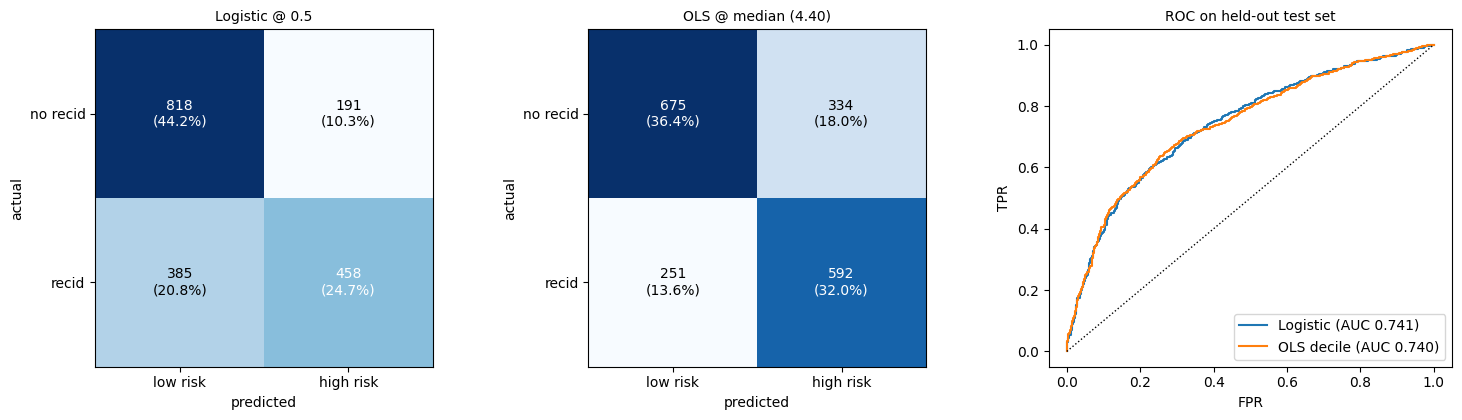

In [6]:
def binary_report(y_true, y_hat, y_score, label):
    return pd.Series({"model": label,
                      "accuracy": accuracy_score(y_true, y_hat),
                      "roc_auc": roc_auc_score(y_true, y_score),
                      "precision": precision_score(y_true, y_hat, zero_division=0),
                      "recall": recall_score(y_true, y_hat, zero_division=0),
                      "f1": f1_score(y_true, y_hat, zero_division=0)})

test_pred_decile = model_ols.predict(X_test)                       # Model A output (continuous)
test_prob_recid  = model_logit.predict_proba(X_test)[:, 1]         # Model B output (probability)
ols_median_cut   = float(np.median(test_pred_decile))
flag_A = (test_pred_decile >= ols_median_cut).astype(int)          # median threshold on OLS
flag_B = (test_prob_recid >= 0.5).astype(int)                      # 0.5 threshold on logit

metric_table = pd.DataFrame([
    binary_report(y_test_bin, flag_B, test_prob_recid, "B: Logistic @ 0.5"),
    binary_report(y_test_bin, flag_A, test_pred_decile, "A: OLS decile @ median"),
    binary_report(y_test_bin, (test_frame["decile_score"] >= 5).astype(int), test_frame["decile_score"],
                  "Reference: COMPAS decile >= 5")]).set_index("model")
display(save_table(metric_table, "p1_test_metrics"))

ols_fit_stats = {"test_r2": r2_score(y_test_score, test_pred_decile),
                 "test_rmse": mean_squared_error(y_test_score, test_pred_decile) ** 0.5,
                 "median_of_ols_predictions": ols_median_cut}
print("Model A (reproducing decile_score):", {k: round(v, 4) for k, v in ols_fit_stats.items()})
RUN_LOG["test_metrics"] = metric_table.round(5).to_dict("index")
RUN_LOG["ols_fit_stats"] = ols_fit_stats

def draw_confusion(ax, y_true, y_hat, title):
    """Annotated 2x2 confusion matrix (rows = actual, cols = predicted)."""
    cm = confusion_matrix(y_true, y_hat)
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}\n({v / cm.sum():.1%})", ha="center", va="center",
                color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["low risk", "high risk"]); ax.set_yticks([0, 1], ["no recid", "recid"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(title, fontsize=10)
    return cm

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
cm_B = draw_confusion(axes[0], y_test_bin, flag_B, "Logistic @ 0.5")
cm_A = draw_confusion(axes[1], y_test_bin, flag_A, f"OLS @ median ({ols_median_cut:.2f})")
for lab, sc in [("Logistic", test_prob_recid), ("OLS decile", test_pred_decile)]:
    fpr_, tpr_, _ = roc_curve(y_test_bin, sc)
    axes[2].plot(fpr_, tpr_, label=f"{lab} (AUC {roc_auc_score(y_test_bin, sc):.3f})")
axes[2].plot([0, 1], [0, 1], "k:", lw=1); axes[2].set_xlabel("FPR"); axes[2].set_ylabel("TPR")
axes[2].set_title("ROC on held-out test set", fontsize=10); axes[2].legend(loc="lower right")
fig.tight_layout(); save_figure(fig, "p1_confusion_and_roc"); plt.show()

,Logit-0.5: low,Logit-0.5: high
OLS-median: low,914,12
OLS-median: high,289,637


{'n_test': 1852, 'n_mismatch': 301, 'pct_mismatch': 16.253, 'n_A_high_B_low': 289, 'n_A_low_B_high': 12, 'flag_rate_A': 0.5, 'flag_rate_B': 0.35, 'median_cut_A': 4.4, 'agreement_pct': 83.747}


,n,mean_age,mean_priors,share_african_american,actual_recid_rate,mean_ols_pred,mean_logit_prob
bucket,,,,,,,
A high / B low,289,26.0346,1.1765,0.7370,0.4706,4.8644,0.4459
A low / B high,12,45.0833,7.9167,0.1667,0.1667,4.1505,0.5209
agree,1551,36.0999,3.4365,0.4494,0.4545,4.2977,0.4505


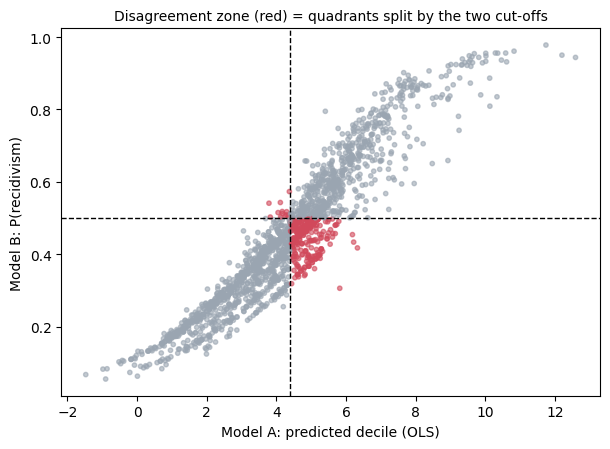

In [7]:
def compare_two_flaggers(flag_first, flag_second, names=("OLS-median", "Logit-0.5")):
    xt = pd.crosstab(pd.Series(flag_first, name=names[0]), pd.Series(flag_second, name=names[1]))
    xt = xt.reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    xt.index = [f"{names[0]}: low", f"{names[0]}: high"]; xt.columns = [f"{names[1]}: low", f"{names[1]}: high"]
    n_total = int(xt.values.sum()); n_disagree = int(xt.values[0, 1] + xt.values[1, 0])
    return xt, {"n_test": n_total, "n_mismatch": n_disagree, "pct_mismatch": 100 * n_disagree / n_total,
                "n_A_high_B_low": int(xt.values[1, 0]), "n_A_low_B_high": int(xt.values[0, 1])}

mismatch_xt, mismatch_stats = compare_two_flaggers(flag_A, flag_B)
display(mismatch_xt)
mismatch_stats.update({"flag_rate_A": float(flag_A.mean()), "flag_rate_B": float(flag_B.mean()),
                       "median_cut_A": ols_median_cut, "agreement_pct": 100 - mismatch_stats["pct_mismatch"]})
print({k: round(v, 3) if isinstance(v, float) else v for k, v in mismatch_stats.items()})
RUN_LOG["mismatch"] = mismatch_stats
save_table(mismatch_xt, "p1_mismatch_confusion")

# who sits in the disagreement zone?
disagree_view = test_frame.assign(ols_pred=test_pred_decile, logit_prob=test_prob_recid,
    bucket=np.select([(flag_A == flag_B), (flag_A == 1) & (flag_B == 0)], ["agree", "A high / B low"], "A low / B high"))
mismatch_profile = disagree_view.groupby("bucket").agg(
    n=("age", "size"), mean_age=("age", "mean"), mean_priors=("priors_count", "mean"),
    share_african_american=("race_african_american", "mean"), actual_recid_rate=("two_year_recid", "mean"),
    mean_ols_pred=("ols_pred", "mean"), mean_logit_prob=("logit_prob", "mean"))
display(save_table(mismatch_profile, "p1_mismatch_profile"))

fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.scatter(test_pred_decile, test_prob_recid, c=np.where(flag_A == flag_B, "#9aa5b1", "#d1495b"), s=10, alpha=.6)
ax.axvline(ols_median_cut, c="k", ls="--", lw=1); ax.axhline(.5, c="k", ls="--", lw=1)
ax.set_xlabel("Model A: predicted decile (OLS)"); ax.set_ylabel("Model B: P(recidivism)")
ax.set_title("Disagreement zone (red) = quadrants split by the two cut-offs", fontsize=10)
fig.tight_layout(); save_figure(fig, "p1_mismatch_scatter"); plt.show()

In [8]:
SUBGROUPS=[("Full sample",train_frame.index),("Under 25",train_frame.index[train_frame.age<25]),("Age 25-45",train_frame.index[(train_frame.age>=25)&(train_frame.age<=45)]),("Over 45",train_frame.index[train_frame.age>45])]
subrows=[]; rng=np.random.default_rng(MASTER_SEED); j=FEATURE_COLUMNS.index("priors_count")
for label,idx in SUBGROUPS:
 Xg,yg=train_frame.loc[idx,FEATURE_COLUMNS],y_train_bin.loc[idx]
 est=make_pipeline(LogisticRegression(penalty="l2",solver="lbfgs",C=logit_search.best_params_["model__C"],max_iter=5000)).fit(Xg,yg)
 draws=[]
 for _ in range(100):
  take=rng.integers(0,len(idx),len(idx))
  if yg.iloc[take].nunique()<2: continue
  b=make_pipeline(LogisticRegression(penalty="l2",solver="lbfgs",C=logit_search.best_params_["model__C"],max_iter=5000)).fit(Xg.iloc[take],yg.iloc[take])
  draws.append(b.named_steps["model"].coef_[0][j])
 subrows.append({"group":label,"n":len(idx),"priors_log_odds_coef":est.named_steps["model"].coef_[0][j],"ci_low":np.percentile(draws,2.5),"ci_high":np.percentile(draws,97.5)})
simpson_table=pd.DataFrame(subrows).set_index("group")
display(save_table(simpson_table,"p2_simpson_subgroup_coefficients"))


,n,priors_log_odds_coef,ci_low,ci_high
group,,,,
Full sample,4320,0.7162,0.6281,0.8237
Under 25,945,0.7457,0.5073,0.9883
Age 25-45,2545,0.8772,0.7294,1.0341
Over 45,830,0.6799,0.5189,0.9092


In [9]:
def logistic_coef_wald(X,y,feature,cols,C):
    scaler=StandardScaler().fit(X); Z=scaler.transform(X)
    model=LogisticRegression(C=C,max_iter=5000).fit(Z,y)
    design=np.column_stack([np.ones(len(Z)),Z]); prob=model.predict_proba(Z)[:,1]; w=prob*(1-prob)
    info=(design.T*w)@design; info[1:,1:]+=np.eye(len(cols))/C
    cov=np.linalg.pinv(info); j=cols.index(feature)+1
    estimate=float(model.coef_[0,j-1]); se=float(np.sqrt(cov[j,j]))
    return estimate,estimate-1.96*se,estimate+1.96*se
race_coef_rows=[]; subgroup_feature="juv_other_count"; full_cols=FEATURE_COLUMNS
for label,mask in [("Full sample",np.ones(len(train_frame),dtype=bool)),("African-American",train_frame.race_group.eq("African-American").to_numpy()),("Caucasian",train_frame.race_group.eq("Caucasian").to_numpy())]:
    use_cols=full_cols if label=="Full sample" else [c for c in full_cols if c not in RACE_DUMMIES]
    Xg=train_frame.loc[mask,use_cols]; yg=y_train_bin.loc[Xg.index]
    coef,lo,hi=logistic_coef_wald(Xg,yg,subgroup_feature,use_cols,logit_search.best_params_["model__C"])
    race_coef_rows.append({"group":label,"n":len(Xg),"predictor":subgroup_feature,"standardized_log_odds_coef":coef,"ci_low":lo,"ci_high":hi})
race_subgroup_coef=pd.DataFrame(race_coef_rows).set_index("group")
display(save_table(race_subgroup_coef,"p2_simpson_race_coefficients"))


,n,predictor,standardized_log_odds_coef,ci_low,ci_high
group,,,,,
Full sample,4320,juv_other_count,0.1189,0.0469,0.1908
African-American,2263,juv_other_count,0.2480,0.1368,0.3592
Caucasian,1414,juv_other_count,-0.0082,-0.1239,0.1076


In [10]:
ovb_full=make_pipeline(LogisticRegression(penalty="l2",solver="lbfgs",C=logit_search.best_params_["model__C"],max_iter=5000)).fit(X_train,y_train_bin)
ovb_feats=[c for c in FEATURE_COLUMNS if c!="priors_count"]
ovb_red=make_pipeline(LogisticRegression(penalty="l2",solver="lbfgs",C=logit_search.best_params_["model__C"],max_iter=5000)).fit(train_frame[ovb_feats],y_train_bin)
ovb_rows=[]
for f in ovb_feats:
 before=float(ovb_full.named_steps["model"].coef_[0][FEATURE_COLUMNS.index(f)]); after=float(ovb_red.named_steps["model"].coef_[0][ovb_feats.index(f)])
 ovb_rows.append({"predictor":f,"full_coef":before,"reduced_coef":after,"pct_change":100*(after-before)/abs(before) if before else np.nan})
ovb_table=pd.DataFrame(ovb_rows).set_index("predictor"); display(save_table(ovb_table,"p2_omitted_variable_bias"))
print("largest absolute shift:",ovb_table.assign(delta=(ovb_table.reduced_coef-ovb_table.full_coef).abs()).delta.idxmax())


,full_coef,reduced_coef,pct_change
predictor,,,
age,-0.5021,-0.3142,37.4244
juv_fel_count,-0.0307,0.0990,422.7390
juv_misd_count,0.0347,0.1830,427.0955
juv_other_count,0.1189,0.1576,32.5888
jail_days,0.0780,0.1724,121.0684
is_felony,0.0689,0.1343,94.7739
is_male,0.1555,0.1906,22.5291
race_african_american,-0.0021,0.1134,5568.6451
race_hispanic,-0.0382,-0.0358,6.3276


largest absolute shift: age


In [11]:
adv_pool=test_frame.assign(y=y_test_bin.to_numpy(),prob=test_prob_recid)
adv_pool=adv_pool[((adv_pool.prob>=.75)&(adv_pool.y==0))|((adv_pool.prob<=.25)&(adv_pool.y==1))].copy()
adv_pool["error_type"]=np.where(adv_pool.y==0,"confident false positive","confident false negative")
adv=adv_pool.sample(n=min(50,len(adv_pool)),random_state=MASTER_SEED)
adv_cols=[c for c in ["age","sex","race_group","priors_count","juv_other_count","prob","y","error_type"] if c in adv.columns]
adv[adv_cols].to_csv(RESULTS_DIR/"p2_adversarial_50_rows.csv",index=False)
print({"eligible_count":len(adv_pool),"eligible_pct_test":100*len(adv_pool)/len(test_frame),"reported_n":len(adv)})
adv_demo=pd.DataFrame({"subset":{"n":len(adv),"mean_age":adv.age.mean(),"female_share":(adv.sex=="Female").mean(),"mean_priors":adv.priors_count.mean(),"african_american_share":(adv.race_group=="African-American").mean()},"full_test":{"n":len(test_frame),"mean_age":test_frame.age.mean(),"female_share":(test_frame.sex=="Female").mean(),"mean_priors":test_frame.priors_count.mean(),"african_american_share":(test_frame.race_group=="African-American").mean()}}).T
display(save_table(adv_demo,"p2_adversarial_demographics"))
adv_profile=adv.groupby("error_type").agg(n=("age","size"),mean_age=("age","mean"),mean_priors=("priors_count","mean"),female_share=("sex",lambda s:(s=="Female").mean()),african_american_share=("race_group",lambda s:(s=="African-American").mean()))
display(save_table(adv_profile,"p2_adversarial_error_profile"))
adv_common=pd.DataFrame({"adversarial_subset":[(adv.priors_count>=5).mean(),(adv.age<25).mean(),(adv.sex=="Female").mean()],"full_test":[(test_frame.priors_count>=5).mean(),(test_frame.age<25).mean(),(test_frame.sex=="Female").mean()]},index=["priors_count >= 5","age < 25","female"])
display(save_table(adv_common,"p2_adversarial_common_traits"))
print("Rows saved:",len(adv),"| subset with priors_count >= 5:",round(100*(adv.priors_count>=5).mean(),1),"%")


{'eligible_count': 78, 'eligible_pct_test': 4.211663066954643, 'reported_n': 50}


,n,mean_age,female_share,mean_priors,african_american_share
subset,50.0,46.3600,0.320,4.4200,0.2600
full_test,1852.0,34.5875,0.189,3.1129,0.4924


,n,mean_age,mean_priors,female_share,african_american_share
error_type,,,,,
confident false negative,36,51.7778,0.6944,0.4444,0.1667
confident false positive,14,32.4286,14.0000,0.0000,0.5000


,adversarial_subset,full_test
priors_count >= 5,0.28,0.2354
age < 25,0.04,0.2171
female,0.32,0.1890


Rows saved: 50 | subset with priors_count >= 5: 28.0 %


,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,n_false_pos,n_false_neg
African-American,912.0,0.5471,0.4868,0.6633,0.2736,0.3367,0.7455,0.6919,113.0,168.0
Caucasian,689.0,0.3788,0.2511,0.4061,0.1565,0.5939,0.6127,0.6778,67.0,155.0


,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,n_false_pos,n_false_neg
Less than 25,402.0,0.5697,0.5299,0.6550,0.3642,0.3450,0.7042,0.6468,63.0,79.0
25 - 45,1047.0,0.4642,0.3610,0.5514,0.1961,0.4486,0.7090,0.6867,110.0,218.0
Greater than 45,403.0,0.3176,0.1439,0.3125,0.0655,0.6875,0.6897,0.7370,18.0,88.0


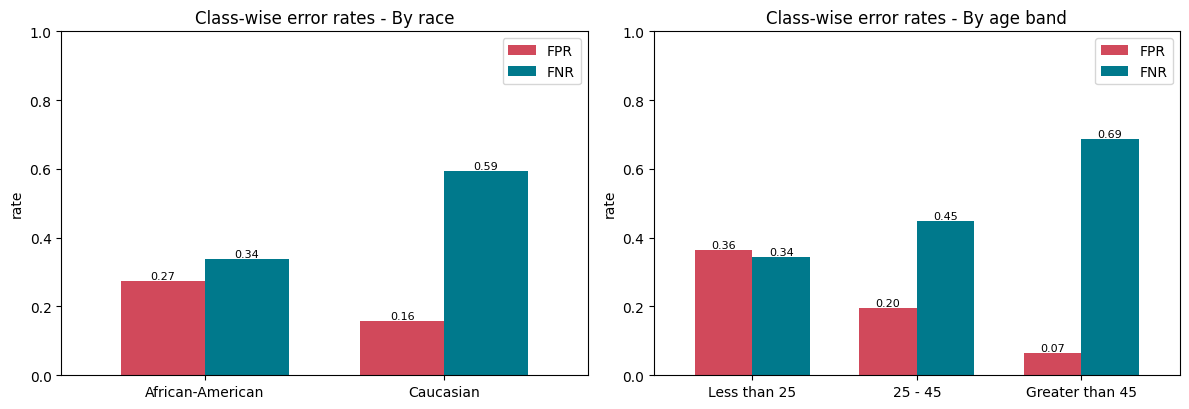

In [12]:
def group_error_profile(frame, y_col, hat_col, group_col):
    rows = {}
    for name, g in frame.groupby(group_col):
        y, p = g[y_col].to_numpy(), g[hat_col].to_numpy()
        tp, fp = ((p == 1) & (y == 1)).sum(), ((p == 1) & (y == 0)).sum()
        fn, tn = ((p == 0) & (y == 1)).sum(), ((p == 0) & (y == 0)).sum()
        rows[name] = {"n": len(g), "base_rate": y.mean(), "selection_rate": p.mean(),
                      "TPR": tp / max(tp + fn, 1), "FPR": fp / max(fp + tn, 1),
                      "FNR": fn / max(tp + fn, 1), "PPV": tp / max(tp + fp, 1) if (tp + fp) else np.nan,
                      "accuracy": (tp + tn) / len(g), "n_false_pos": int(fp), "n_false_neg": int(fn)}
    return pd.DataFrame(rows).T

audit_frame = test_frame.assign(y=y_test_bin.to_numpy(), prob=test_prob_recid, yhat=flag_B)

race_view = audit_frame[audit_frame["race_group"].isin(["African-American", "Caucasian"])]
age_view  = audit_frame.assign(age_band=pd.Categorical(audit_frame["age_cat"],
                               ["Less than 25", "25 - 45", "Greater than 45"], ordered=True))

race_errors = group_error_profile(race_view, "y", "yhat", "race_group")
age_errors  = group_error_profile(age_view,  "y", "yhat", "age_band")
display(save_table(race_errors, "p2_error_rates_by_race"))
display(save_table(age_errors,  "p2_error_rates_by_age"))
RUN_LOG["race_errors"] = race_errors.round(5).to_dict("index")
RUN_LOG["age_errors"]  = age_errors.round(5).to_dict("index")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, tbl, ttl in [(axes[0], race_errors, "By race"), (axes[1], age_errors, "By age band")]:
    tbl[["FPR", "FNR"]].astype(float).plot.bar(ax=ax, rot=0, color=["#d1495b", "#00798c"], width=.7)
    for cont in ax.containers: ax.bar_label(cont, fmt="%.2f", fontsize=8)
    ax.set_ylim(0, 1); ax.set_title(f"Class-wise error rates - {ttl}"); ax.set_ylabel("rate")
fig.tight_layout(); save_figure(fig, "p2_error_rates"); plt.show()

In [13]:
def formal_fairness_table(frame, group_col, reference, y_col="y", hat_col="yhat"):
    prof = group_error_profile(frame, y_col, hat_col, group_col)
    ref = prof.loc[reference]
    out = pd.DataFrame({
        "group": [g for g in prof.index if g != reference],
    }).set_index("group")
    for g in out.index:
        out.loc[g, "disparate_impact_ratio"]  = prof.loc[g, "selection_rate"] / ref["selection_rate"]
        out.loc[g, "demographic_parity_diff"] = prof.loc[g, "selection_rate"] - ref["selection_rate"]
        out.loc[g, "low_risk_DI_ratio"] = (1 - prof.loc[g, "selection_rate"]) / (1 - ref["selection_rate"])
        out.loc[g, "TPR_gap"] = prof.loc[g, "TPR"] - ref["TPR"]
        out.loc[g, "FPR_gap"] = prof.loc[g, "FPR"] - ref["FPR"]
        out.loc[g, "equalized_odds_diff"] = max(abs(out.loc[g, "TPR_gap"]), abs(out.loc[g, "FPR_gap"]))
    out.insert(0, "reference", reference)
    return out

fair_race = formal_fairness_table(race_view, "race_group", "Caucasian")
fair_age  = formal_fairness_table(age_view, "age_band", "25 - 45")
display(save_table(fair_race, "p2_formal_fairness_race"))
display(save_table(fair_age,  "p2_formal_fairness_age"))
RUN_LOG["fair_race"] = fair_race.drop(columns="reference").round(5).to_dict("index")
RUN_LOG["fair_age"]  = fair_age.drop(columns="reference").round(5).to_dict("index")

def bootstrap_gap_ci(frame, group_col, g_a, g_b, n_boot=2000, seed=MASTER_SEED):
    rng = np.random.default_rng(seed)
    parts = {g: frame[frame[group_col] == g][["y", "yhat"]].to_numpy() for g in (g_a, g_b)}
    def rates(arr):
        y, p = arr[:, 0], arr[:, 1]
        neg, pos = (y == 0), (y == 1)
        return p.mean(), p[neg].mean(), 1 - p[pos].mean()
    draws = []
    for _ in range(n_boot):
        ra = rates(parts[g_a][rng.integers(0, len(parts[g_a]), len(parts[g_a]))])
        rb = rates(parts[g_b][rng.integers(0, len(parts[g_b]), len(parts[g_b]))])
        draws.append([ra[0] - rb[0], ra[1] - rb[1], ra[2] - rb[2]])
    draws = np.array(draws)
    point = np.array([a - b for a, b in zip(rates(parts[g_a]), rates(parts[g_b]))])
    lo, hi = np.percentile(draws, [2.5, 97.5], axis=0)
    return pd.DataFrame({"gap_point": point, "ci_low": lo, "ci_high": hi},
                        index=["selection_rate_gap", "FPR_gap", "FNR_gap"])

ci_race = bootstrap_gap_ci(race_view, "race_group", "African-American", "Caucasian")
display(save_table(ci_race, "p2_bootstrap_gap_ci_race"))
RUN_LOG["bootstrap_ci_race"] = ci_race.round(5).to_dict("index")
print("A gap whose 95% interval excludes 0 is unlikely to be sampling noise.")

,reference,disparate_impact_ratio,demographic_parity_diff,low_risk_DI_ratio,TPR_gap,FPR_gap,equalized_odds_diff
group,,,,,,,
African-American,Caucasian,1.9389,0.2358,0.6852,0.2572,0.1171,0.2572


,reference,disparate_impact_ratio,demographic_parity_diff,low_risk_DI_ratio,TPR_gap,FPR_gap,equalized_odds_diff
group,,,,,,,
Less than 25,25 - 45,1.4676,0.1688,0.7358,0.1036,0.1681,0.1681
Greater than 45,25 - 45,0.3986,-0.2171,1.3398,-0.2389,-0.1306,0.2389


,gap_point,ci_low,ci_high
selection_rate_gap,0.2358,0.1913,0.2823
FPR_gap,0.1171,0.0645,0.1735
FNR_gap,-0.2572,-0.3279,-0.1781


A gap whose 95% interval excludes 0 is unlikely to be sampling noise.


In [14]:
# Sensitivity: does removing race (and sex) from the feature list remove the disparity?
BLIND_FEATURES = [c for c in FEATURE_COLUMNS if c not in RACE_DUMMIES and c != "is_male"]
blind_search = GridSearchCV(
    make_pipeline(LogisticRegression(penalty="l2", solver="lbfgs", max_iter=5000)),
    logit_grid, scoring="roc_auc", cv=strat_cv, n_jobs=-1).fit(train_frame[BLIND_FEATURES], y_train_bin)
blind_prob = blind_search.best_estimator_.predict_proba(test_frame[BLIND_FEATURES])[:, 1]
blind_view = test_frame.assign(y=y_test_bin.to_numpy(), yhat=(blind_prob >= 0.5).astype(int))
blind_view = blind_view[blind_view["race_group"].isin(["African-American", "Caucasian"])]

blind_prof = group_error_profile(blind_view, "y", "yhat", "race_group")
blind_fair = formal_fairness_table(blind_view, "race_group", "Caucasian")
compare_blind = pd.DataFrame({
    "with_race_sex": [race_errors.loc["African-American", "FPR"], race_errors.loc["Caucasian", "FPR"],
                      fair_race.loc["African-American", "disparate_impact_ratio"],
                      fair_race.loc["African-American", "equalized_odds_diff"]],
    "without_race_sex": [blind_prof.loc["African-American", "FPR"], blind_prof.loc["Caucasian", "FPR"],
                         blind_fair.loc["African-American", "disparate_impact_ratio"],
                         blind_fair.loc["African-American", "equalized_odds_diff"]]},
    index=["FPR African-American", "FPR Caucasian", "Disparate impact ratio (AA/Cauc)", "Equalized odds diff"]).astype(float)
display(save_table(compare_blind, "p2_unawareness_check"))
RUN_LOG["unawareness"] = compare_blind.round(5).to_dict("index")

,with_race_sex,without_race_sex
FPR African-American,0.2736,0.2228
FPR Caucasian,0.1565,0.1285
Disparate impact ratio (AA/Cauc),1.9389,1.9399
Equalized odds diff,0.2572,0.2301


,threshold,DP,EO,PP,TPR_ratio,FPR_ratio,sel_A,sel_B,FPR_A,FPR_B,PPV_A,PPV_B,accuracy
0,0.05,1.0000,1.0000,0.6923,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.3788,0.5471,0.4747
1,0.15,0.9560,0.9506,0.7048,0.9732,0.9506,0.9434,0.9868,0.9276,0.9758,0.3892,0.5522,0.4941
2,0.25,0.8176,0.7897,0.7548,0.8914,0.7897,0.7692,0.9408,0.7056,0.8935,0.4302,0.5699,0.5540
3,0.35,0.7095,0.6960,0.7858,0.8052,0.6960,0.5835,0.8224,0.4836,0.6949,0.4851,0.6173,0.6277
4,0.45,0.5836,0.6340,0.7866,0.6631,0.6340,0.3628,0.6217,0.2640,0.4165,0.5480,0.6966,0.6796
5,0.55,0.4438,0.4825,0.8695,0.5573,0.4825,0.1669,0.3761,0.0841,0.1743,0.6870,0.7901,0.6765
6,0.65,0.3871,0.3366,0.9509,0.5317,0.3366,0.0900,0.2325,0.0350,0.1041,0.7581,0.7972,0.6240
7,0.75,0.2692,0.3218,0.8276,0.3218,0.3973,0.0348,0.1294,0.0164,0.0412,0.7083,0.8559,0.5840
8,0.85,0.3496,0.4156,0.8230,0.4156,0.5514,0.0203,0.0581,0.0093,0.0169,0.7143,0.8679,0.5534
9,0.95,0.1891,0.2731,1.0000,0.2731,NaN,0.0015,0.0077,0.0000,0.0000,1.0000,1.0000,0.5303


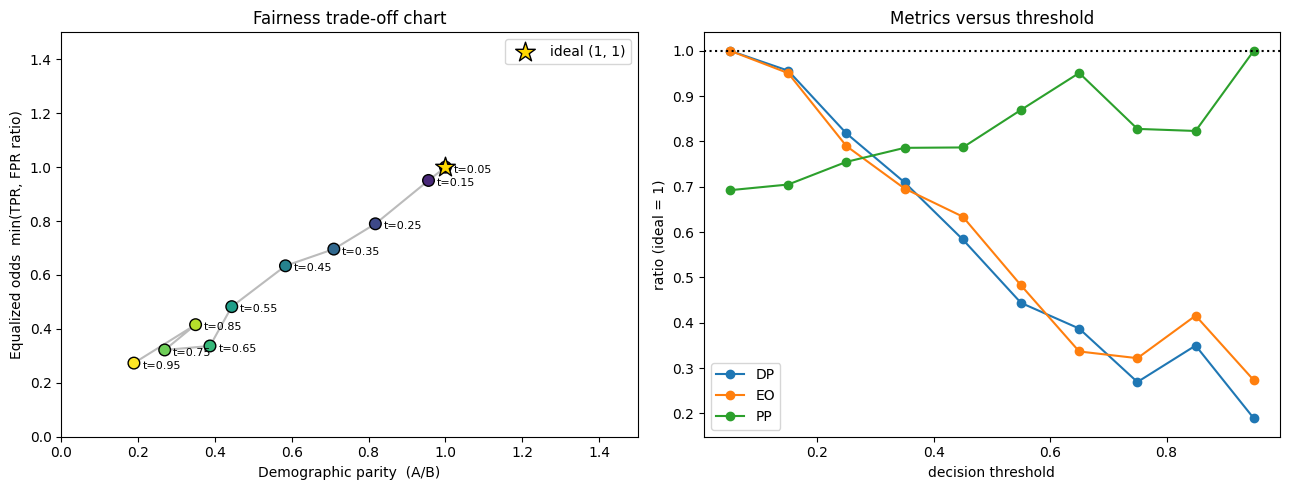

{'move': 't=0.65 -> t=0.35', 'improved': 'DP', 'harmed': 'PP', 'DP_from_to': (np.float64(0.387), np.float64(0.709)), 'PP_from_to': (np.float64(0.951), np.float64(0.786)), 'Z_gain_pct': np.float64(52.6), 'W_loss_pct': np.float64(336.7), 'abs_gap_closed': np.float64(0.322), 'abs_gap_opened': np.float64(0.165), 'cost_W_over_Z': np.float64(6.4)}
{'move': 't=0.65 -> t=0.35', 'improved': 'EO', 'harmed': 'PP', 'EO_from_to': (np.float64(0.337), np.float64(0.696)), 'PP_from_to': (np.float64(0.951), np.float64(0.786)), 'Z_gain_pct': np.float64(54.2), 'W_loss_pct': np.float64(336.7), 'abs_gap_closed': np.float64(0.359), 'abs_gap_opened': np.float64(0.165), 'cost_W_over_Z': np.float64(6.22)}
smallest worst-case gap at t = 0.25 | worst gap = 0.245 | accuracy = 0.554 | (t=0.05 flags everyone: accuracy 0.4747 )


,threshold,DP,EO,PP,TPR_ratio,FPR_ratio,sel_A,sel_B,FPR_A,FPR_B,PPV_A,PPV_B,accuracy,worst_gap
0,0.05,1.0000,1.0000,0.6923,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.3788,0.5471,0.4747,0.3077
1,0.15,0.9560,0.9506,0.7048,0.9732,0.9506,0.9434,0.9868,0.9276,0.9758,0.3892,0.5522,0.4941,0.2952
2,0.25,0.8176,0.7897,0.7548,0.8914,0.7897,0.7692,0.9408,0.7056,0.8935,0.4302,0.5699,0.5540,0.2452
3,0.35,0.7095,0.6960,0.7858,0.8052,0.6960,0.5835,0.8224,0.4836,0.6949,0.4851,0.6173,0.6277,0.3040
4,0.45,0.5836,0.6340,0.7866,0.6631,0.6340,0.3628,0.6217,0.2640,0.4165,0.5480,0.6966,0.6796,0.4164
5,0.55,0.4438,0.4825,0.8695,0.5573,0.4825,0.1669,0.3761,0.0841,0.1743,0.6870,0.7901,0.6765,0.5562
6,0.65,0.3871,0.3366,0.9509,0.5317,0.3366,0.0900,0.2325,0.0350,0.1041,0.7581,0.7972,0.6240,0.6634
7,0.75,0.2692,0.3218,0.8276,0.3218,0.3973,0.0348,0.1294,0.0164,0.0412,0.7083,0.8559,0.5840,0.7308
8,0.85,0.3496,0.4156,0.8230,0.4156,0.5514,0.0203,0.0581,0.0093,0.0169,0.7143,0.8679,0.5534,0.6504
9,0.95,0.1891,0.2731,1.0000,0.2731,NaN,0.0015,0.0077,0.0000,0.0000,1.0000,1.0000,0.5303,0.8109


In [15]:
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.10), 2)      # 0.05, 0.15, ..., 0.95 (assignment 2.4)
GROUP_A, GROUP_B = "Caucasian", "African-American"          # ratios are reported as A / B

def safe_ratio(numer, denom):
    return np.nan if (denom is None or np.isnan(denom) or denom == 0) else numer / denom

def threshold_sweep(frame, prob_col, group_col, grp_a, grp_b, thresholds):
    rows = []
    for t in thresholds:
        pooled_hat = (frame[prob_col] >= t).astype(int)
        stats = {}
        for tag, grp in (("A", grp_a), ("B", grp_b)):
            sub = frame[frame[group_col] == grp]
            yh, y = (sub[prob_col] >= t).astype(int).to_numpy(), sub["y"].to_numpy()
            stats[tag] = {"sel": yh.mean(), "tpr": yh[y == 1].mean(), "fpr": yh[y == 0].mean(),
                          "ppv": y[yh == 1].mean() if yh.sum() else np.nan}
        tpr_r = safe_ratio(stats["A"]["tpr"], stats["B"]["tpr"])
        fpr_r = safe_ratio(stats["A"]["fpr"], stats["B"]["fpr"])
        rows.append({"threshold": t,
                     "DP": safe_ratio(stats["A"]["sel"], stats["B"]["sel"]),
                     "EO": np.nanmin([tpr_r, fpr_r]),
                     "PP": safe_ratio(stats["A"]["ppv"], stats["B"]["ppv"]),
                     "TPR_ratio": tpr_r, "FPR_ratio": fpr_r,
                     "sel_A": stats["A"]["sel"], "sel_B": stats["B"]["sel"],
                     "FPR_A": stats["A"]["fpr"], "FPR_B": stats["B"]["fpr"],
                     "PPV_A": stats["A"]["ppv"], "PPV_B": stats["B"]["ppv"],
                     "accuracy": accuracy_score(frame["y"], pooled_hat)})
    return pd.DataFrame(rows)

sweep_table = threshold_sweep(race_view, "prob", "race_group", GROUP_A, GROUP_B, THRESHOLDS)
display(save_table(sweep_table, "p2_threshold_sweep", index=False))
RUN_LOG["sweep"] = sweep_table.round(5).to_dict("records")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ok = sweep_table.dropna(subset=["DP", "EO"])
axes[0].plot(ok.DP, ok.EO, "-", c="#bbbbbb", zorder=1)
axes[0].scatter(ok.DP, ok.EO, c=ok.threshold, cmap="viridis", s=70, edgecolor="k", zorder=2)
for _, r in ok.iterrows():
    axes[0].annotate(f"t={r.threshold:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=(6, -4), fontsize=8)
axes[0].scatter([1], [1], marker="*", s=220, c="gold", edgecolor="k", label="ideal (1, 1)", zorder=3)
axes[0].set_xlim(0, 1.5); axes[0].set_ylim(0, 1.5); axes[0].set_xlabel("Demographic parity  (A/B)")
axes[0].set_ylabel("Equalized odds  min(TPR, FPR ratio)"); axes[0].legend(); axes[0].set_title("Fairness trade-off chart")
for col in ["DP", "EO", "PP"]:
    axes[1].plot(sweep_table.threshold, sweep_table[col], marker="o", label=col)
axes[1].axhline(1, c="k", ls=":"); axes[1].set_xlabel("decision threshold"); axes[1].set_ylabel("ratio (ideal = 1)")
axes[1].legend(); axes[1].set_title("Metrics versus threshold")
fig.tight_layout(); save_figure(fig, "p2_fairness_tradeoff"); plt.show()

def quantify_tradeoff(tbl, t_from, t_to, improved, harmed):
    ix = tbl.set_index("threshold")
    gap = lambda col, t: abs(1 - ix.loc[t, col])
    z = 100 * (gap(improved, t_from) - gap(improved, t_to)) / gap(improved, t_from)
    w = 100 * (gap(harmed, t_to) - gap(harmed, t_from)) / gap(harmed, t_from)
    return {"move": f"t={t_from} -> t={t_to}", "improved": improved, "harmed": harmed,
            f"{improved}_from_to": (round(ix.loc[t_from, improved], 3), round(ix.loc[t_to, improved], 3)),
            f"{harmed}_from_to": (round(ix.loc[t_from, harmed], 3), round(ix.loc[t_to, harmed], 3)),
            "Z_gain_pct": round(z, 1), "W_loss_pct": round(w, 1),
            "abs_gap_closed": round(gap(improved, t_from) - gap(improved, t_to), 3),
            "abs_gap_opened": round(gap(harmed, t_to) - gap(harmed, t_from), 3),
            "cost_W_over_Z": round(w / z, 2)}

tradeoff_rows = [quantify_tradeoff(sweep_table, 0.65, 0.35, "DP", "PP"),
                 quantify_tradeoff(sweep_table, 0.65, 0.35, "EO", "PP")]
for row in tradeoff_rows: print(row)
RUN_LOG["tradeoffs"] = tradeoff_rows

# which single threshold sits closest to ideal on all three metrics, and what does it cost in accuracy?
sweep_table["worst_gap"] = sweep_table[["DP", "EO", "PP"]].sub(1).abs().max(axis=1)
best_row = sweep_table.loc[sweep_table["worst_gap"].idxmin()]
print("smallest worst-case gap at t =", best_row.threshold, "| worst gap =", round(best_row.worst_gap, 3),
      "| accuracy =", round(best_row.accuracy, 4), "| (t=0.05 flags everyone: accuracy",
      round(sweep_table.loc[0, "accuracy"], 4), ")")
save_table(sweep_table, "p2_threshold_sweep", index=False)

In [16]:
with open(RESULTS_DIR / "run_summary.json", "w") as fh:
    json.dump(RUN_LOG, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

print("Analysis complete. Tables are in results/ and figures are in plots/.")


Analysis complete. Tables are in results/ and figures are in plots/.
